[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/21_cnns.ipynb)

# 21 · Convolutional Neural Networks: Building In What We Know About Images

**Part 3 — Deep learning** · Notebook 21 of 27

An MLP looks at an image as a list of 784 unrelated numbers. Shuffle the pixels, the same way for every image, and the MLP doesn't care: it learns just as well, because it never used the fact that neighboring pixels belong together. That's a lot of wasted knowledge. We *know* two things about images: **local patterns matter** (edges, corners, textures are made of nearby pixels), and **a pattern means the same thing wherever it appears** (an edge in the top-left corner is still an edge in the bottom-right).

A **convolutional neural network** (CNN) builds both facts into its architecture. Instead of connecting every pixel to every unit, it slides small learned filters across the image, reusing the same weights everywhere. The result has far fewer parameters, learns faster from less data, and handles shifted inputs gracefully. CNNs started the deep learning boom in 2012 and are still the workhorse of image processing.

**What you'll learn**

1. The pixel-shuffle test: what an MLP ignores
2. Convolution from scratch: sliding a filter, edge detectors
3. Padding, stride, and the output-size formula
4. Convolution layers: channels, filters, parameters
5. Pooling and (approximate) translation invariance
6. A CNN for Fashion-MNIST, compared with the MLP
7. What the filters learn, and what the feature maps show
8. Receptive fields: seeing more with depth
9. Data augmentation
10. Deeper networks: VGG blocks, batch norm, and **residual connections**
11. What is the network looking at? Saliency and occlusion

*Course map: CX 4240 lecture 12 (convolutional neural networks: MLPs ruin spatial structure, convolution layers, filters, padding and stride, activation maps, max and mean pooling, the full CNN pipeline) and ISYE 4600 W10 (convolution layers and features, pooling, translation invariance and parameter efficiency, AlexNet and ImageNet, residual networks).*

In [1]:
#@title ⚙️ Setup — run this cell first (imports, plot style, helpers)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display, Markdown
import ipywidgets as widgets
from ipywidgets import interact, FloatSlider, IntSlider

# One consistent, colorblind-checked palette used across the whole series
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#4a3aa7", red="#e34948",
         ink="#0b0b0b", muted="#52514e", light="#d9d8d3")
plt.rcParams.update({
    "figure.figsize": (6.4, 4.2), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.prop_cycle": plt.cycler(color=[C[k] for k in
        ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]),
    "lines.linewidth": 2, "font.size": 11, "legend.frameon": False,
    "animation.embed_limit": 40, "animation.frame_format": "jpeg",   # JPEG frames keep notebooks small
})

def show_anim(anim):
    """Render a matplotlib animation as an interactive player (play / pause / scrub)."""
    plt.close(anim._fig)
    return HTML(anim.to_jshtml(default_mode="once"))

rng = np.random.default_rng(0)
print("Setup complete ✓")
import torch, torch.nn as nn, torch.nn.functional as F
import time, gzip, os, urllib.request
from sklearn.datasets import load_sample_image
torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"PyTorch {torch.__version__} on {device}")

FMNIST_URL = "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"
CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
def load_fashion_mnist(root="data/fashion"):
    os.makedirs(root, exist_ok=True); out = {}
    for split, prefix in [("train", "train"), ("test", "t10k")]:
        for kind, offset in [("images", 16), ("labels", 8)]:
            fname = f"{prefix}-{kind}-idx{3 if kind == 'images' else 1}-ubyte.gz"; path = os.path.join(root, fname)
            if not os.path.exists(path): urllib.request.urlretrieve(FMNIST_URL + fname, path)
            out[(split, kind)] = np.frombuffer(gzip.open(path).read(), np.uint8, offset=offset)
    return (out[("train", "images")].reshape(-1, 1, 28, 28), out[("train", "labels")],
            out[("test", "images")].reshape(-1, 1, 28, 28), out[("test", "labels")])
print("Ready ✓")

Setup complete ✓


PyTorch 2.14.1+cu130 on cpu
Ready ✓


We reuse notebook 20's data pipeline and training loop. As before, the default trains on a 20,000-image subset so it runs in a few minutes on a CPU; on a GPU runtime set `N_TRAIN = 55000`.

In [2]:
from torch.utils.data import TensorDataset, DataLoader
Xtr_all, ytr_all, Xte_np, yte_np = load_fashion_mnist()
N_TRAIN = 20000                                  # 55000 on a GPU runtime
perm = np.random.default_rng(0).permutation(len(Xtr_all)); val_idx, tr_idx = perm[:5000], perm[5000:5000 + N_TRAIN]
mean, std = Xtr_all[tr_idx].mean() / 255, Xtr_all[tr_idx].std() / 255
to_tensor = lambda X: (torch.tensor(X, dtype=torch.float32) / 255 - mean) / std
Xtr_t, ytr_t = to_tensor(Xtr_all[tr_idx]), torch.tensor(ytr_all[tr_idx], dtype=torch.long)
Xva_t, yva_t = to_tensor(Xtr_all[val_idx]), torch.tensor(ytr_all[val_idx], dtype=torch.long)
Xte_t, yte_t = to_tensor(Xte_np), torch.tensor(yte_np, dtype=torch.long)
val_dl, test_dl = DataLoader(TensorDataset(Xva_t, yva_t), batch_size=1000), DataLoader(TensorDataset(Xte_t, yte_t), batch_size=1000)

def evaluate(model, dl):
    model.eval(); correct, total, loss_sum = 0, 0, 0.0
    with torch.no_grad():
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device); out = model(xb)
            loss_sum += F.cross_entropy(out, yb, reduction="sum").item(); correct += (out.argmax(1) == yb).sum().item(); total += len(yb)
    return loss_sum / total, correct / total

def fit(model, X, y, epochs=6, lr=2e-3, wd=1e-4, batch=128, augment=None, verbose=True, seed=0, val=None):
    torch.manual_seed(seed); model.to(device)
    dl = DataLoader(TensorDataset(X, y), batch_size=batch, shuffle=True)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * len(dl))
    hist = []
    for ep in range(epochs):
        model.train(); t0 = time.time(); tl, n = 0.0, 0
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            if augment is not None: xb = augment(xb)
            loss = F.cross_entropy(model(xb), yb); opt.zero_grad(); loss.backward(); opt.step(); sched.step()
            tl += loss.item() * len(yb); n += len(yb)
        vl, va = evaluate(model, val if val is not None else val_dl)
        hist.append(dict(epoch=ep + 1, train_loss=tl / n, val_loss=vl, val_acc=va))
        if verbose: print(f"epoch {ep + 1}: train loss {tl / n:.3f}  val loss {vl:.3f}  val acc {va:.1%}  ({time.time() - t0:.1f}s)")
    return pd.DataFrame(hist)

n_params = lambda m: sum(p.numel() for p in m.parameters())
print(f"{len(Xtr_t):,} training images, {len(Xva_t):,} validation, {len(Xte_t):,} test")

20,000 training images, 5,000 validation, 10,000 test


---
## 1. The pixel-shuffle test

Pick one random permutation of the 784 pixel positions and apply it to **every** image, training and test alike. To a person the result is noise. To an MLP it's exactly the same problem: its first layer connects every input to every unit, so it has no notion of which pixels are neighbors, and reordering the inputs just reorders its weights.

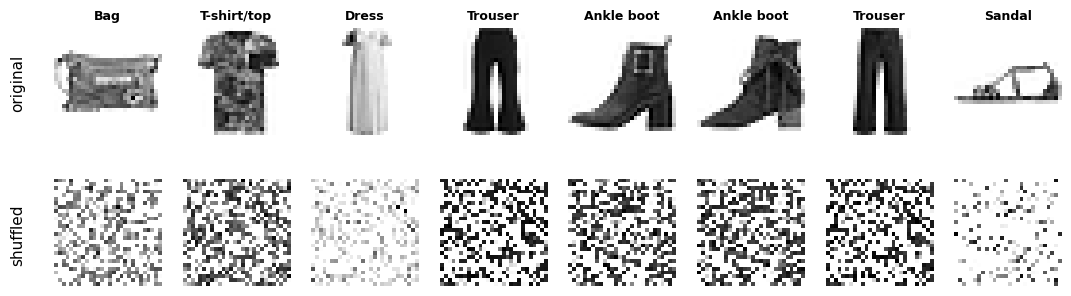

,original images,pixels shuffled
MLP,86.6%,86.9%
CNN,89.4%,86.5%


In [3]:
pix_perm = torch.from_numpy(np.random.default_rng(1).permutation(784))
shuffle_px = lambda X: X.flatten(1)[:, pix_perm].reshape(-1, 1, 28, 28)

fig, axes = plt.subplots(2, 8, figsize=(13, 3.6))
for k in range(8):
    axes[0, k].imshow(Xtr_t[k, 0], cmap="gray_r"); axes[1, k].imshow(shuffle_px(Xtr_t[k:k + 1])[0, 0], cmap="gray_r")
    axes[0, k].set_title(CLASSES[ytr_t[k]], fontsize=9)
    for a in axes[:, k]: a.axis("off")
axes[0, 0].text(-12, 14, "original", rotation=90, va="center"); axes[1, 0].text(-12, 14, "shuffled", rotation=90, va="center")
plt.show()

mlp_fn = lambda: nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU(), nn.Linear(256, 128), nn.ReLU(), nn.Linear(128, 10))
small_cnn_fn = lambda: nn.Sequential(nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                                     nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                                     nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Linear(128, 10))
shuffle_results = {}
val_shuf = DataLoader(TensorDataset(shuffle_px(Xva_t), yva_t), batch_size=1000)
for name, fn in [("MLP", mlp_fn), ("CNN", small_cnn_fn)]:
    a_orig = fit(fn(), Xtr_t, ytr_t, epochs=4, verbose=False).val_acc.iloc[-1]
    a_shuf = fit(fn(), shuffle_px(Xtr_t), ytr_t, epochs=4, verbose=False, val=val_shuf).val_acc.iloc[-1]
    shuffle_results[name] = {"original images": a_orig, "pixels shuffled": a_shuf}
pd.DataFrame(shuffle_results).T.style.format("{:.1%}")

The MLP scores essentially the same on shuffled pixels as on real images: it was never using the spatial arrangement at all. The CNN (which we'll build piece by piece below) does clearly better on real images, and on shuffled pixels its advantage disappears: it falls back to MLP level, because its whole design assumes neighboring pixels are related, and that assumption is now false. A model that can't tell an image from noise is wasting information we could have given it for free.

---
## 2. Convolution from scratch

A **convolution** slides a small grid of weights (a **filter** or **kernel**) over the image. At each position, it multiplies the filter by the patch of pixels under it, element by element, and sums: one output number per position. The output is a new image, the **feature map** (or activation map), that is large wherever the patch resembles the filter (ISYE W10, CX lecture 12):

$$O[i, j] = \sum_{u=-d}^{d}\sum_{v=-d}^{d} I[i + u,\, j + v]\; K[u, v] \;+\; b.$$

(Strictly, this is *cross-correlation*; mathematical convolution flips the kernel first. Deep learning libraries all compute the version above and call it convolution; since the kernel is learned, the flip doesn't matter.)

In [4]:
def conv2d_naive(img, kernel, stride=1, padding=0):
    """Plain loops, exactly the formula: slide the kernel, multiply, sum."""
    img = np.pad(img, padding); kh, kw = kernel.shape
    H = (img.shape[0] - kh) // stride + 1; W = (img.shape[1] - kw) // stride + 1
    out = np.zeros((H, W))
    for i in range(H):
        for j in range(W):
            patch = img[i * stride:i * stride + kh, j * stride:j * stride + kw]
            out[i, j] = (patch * kernel).sum()
    return out

# A tiny example we can follow by eye: a vertical edge
tiny = np.zeros((6, 6)); tiny[:, 3:] = 1.0
k_vert = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], float)       # responds to dark→bright, left to right
out = conv2d_naive(tiny, k_vert)
print("input (6×6):\n", tiny.astype(int)); print("\nkernel:\n", k_vert.astype(int)); print("\noutput (4×4):\n", out.astype(int))

input (6×6):
 [[0 0 0 1 1 1]
 [0 0 0 1 1 1]
 [0 0 0 1 1 1]
 [0 0 0 1 1 1]
 [0 0 0 1 1 1]
 [0 0 0 1 1 1]]

kernel:
 [[-1  0  1]
 [-1  0  1]
 [-1  0  1]]

output (4×4):
 [[0 3 3 0]
 [0 3 3 0]
 [0 3 3 0]
 [0 3 3 0]]


The output is zero over flat regions and large (3) exactly where the window straddles the edge. Let's watch the sliding happen:

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.4), gridspec_kw=dict(width_ratios=[1.4, 0.8, 1]))
def frame_c(t):
    for a in axes: a.clear()
    i, j = divmod(t, 4)
    axes[0].imshow(tiny, cmap="gray_r", vmin=-0.2, vmax=1.2)
    for (r, c), v in np.ndenumerate(tiny): axes[0].text(c, r, int(v), ha="center", va="center", color=C["red"] if v else C["muted"])
    axes[0].add_patch(plt.Rectangle((j - 0.5, i - 0.5), 3, 3, fill=False, ec=C["orange"], lw=3)); axes[0].set_title("input, with the 3×3 window")
    axes[1].imshow(k_vert, cmap="RdBu_r", vmin=-1.5, vmax=1.5)
    for (r, c), v in np.ndenumerate(k_vert): axes[1].text(c, r, int(v), ha="center", va="center", fontsize=12)
    axes[1].set_title("kernel")
    shown = np.full((4, 4), np.nan); shown.flat[:t + 1] = out.flat[:t + 1]
    axes[2].imshow(shown, cmap="viridis", vmin=0, vmax=3)
    for (r, c), v in np.ndenumerate(shown):
        if not np.isnan(v): axes[2].text(c, r, int(v), ha="center", va="center", color="white" if v < 2 else "k", fontsize=12)
    axes[2].add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, ec=C["orange"], lw=3))
    patch = tiny[i:i + 3, j:j + 3]
    axes[2].set_title(f"output[{i},{j}] = Σ patch × kernel = {int((patch * k_vert).sum())}")
    for a in axes: a.set_xticks([]); a.set_yticks([]); a.grid(False)
anim = animation.FuncAnimation(fig, frame_c, frames=16, interval=500)
show_anim(anim)

### Classic hand-designed filters

Before CNNs, computer vision was largely the art of designing filters like these by hand. Here are six classics and their feature maps on a photo:

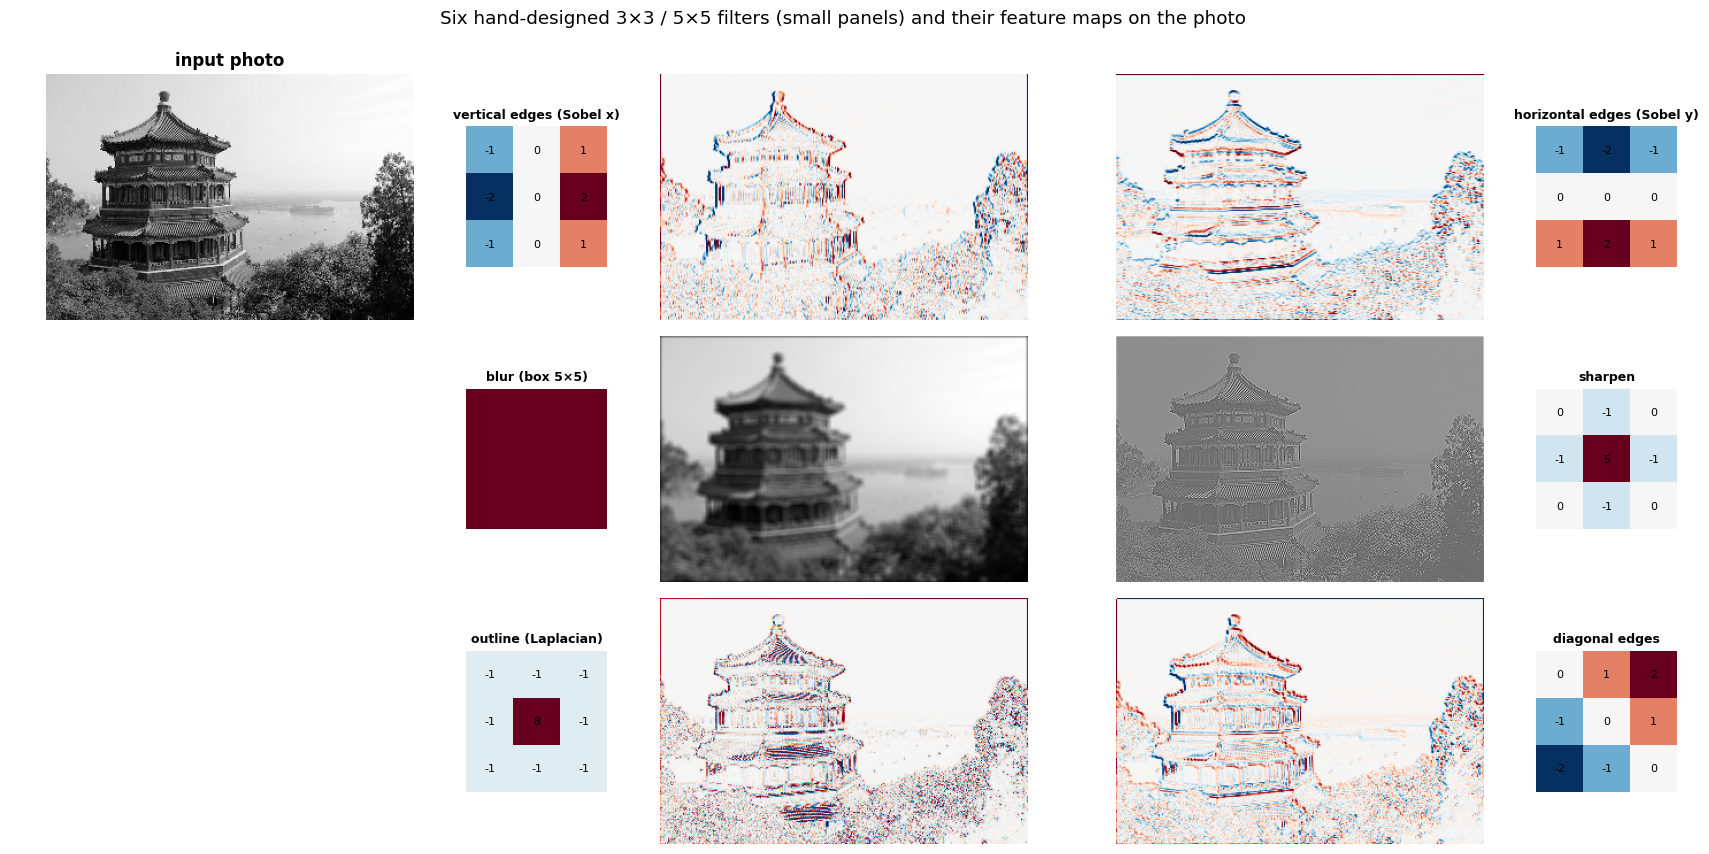

In [6]:
photo = load_sample_image("china.jpg").mean(2)[::2, ::2] / 255.0        # grayscale, 214 × 320
filters = {
    "vertical edges (Sobel x)":   np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], float),
    "horizontal edges (Sobel y)": np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], float),
    "blur (box 5×5)":             np.ones((5, 5)) / 25,
    "sharpen":                    np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], float),
    "outline (Laplacian)":        np.array([[-1, -1, -1], [-1, 8, -1], [-1, -1, -1]], float),
    "diagonal edges":             np.array([[0, 1, 2], [-1, 0, 1], [-2, -1, 0]], float),
}
fig, axes = plt.subplots(3, 5, figsize=(17, 8.6), gridspec_kw=dict(width_ratios=[1, 0.32, 1, 1, 0.32]))
photo_t = torch.tensor(photo, dtype=torch.float32)[None, None]
for row in range(3):
    axes[row, 0].axis("off")
for k, (name, kern) in enumerate(filters.items()):
    row, col = k // 2, (k % 2) * 3                           # each filter: [kernel | feature map], two per row
    kax, fax = (axes[row, 1], axes[row, 2]) if col == 0 else (axes[row, 4], axes[row, 3])
    fmap = F.conv2d(photo_t, torch.tensor(kern, dtype=torch.float32)[None, None], padding=kern.shape[0] // 2)[0, 0].numpy()
    v = np.abs(kern).max(); kax.imshow(kern, cmap="RdBu_r", vmin=-v, vmax=v); kax.set_title(name, fontsize=9)
    if kern.shape[0] <= 3:
        for (r, c), val in np.ndenumerate(kern): kax.text(c, r, f"{val:g}", ha="center", va="center", fontsize=8)
    smooth = "blur" in name or "sharpen" in name; lim = np.percentile(np.abs(fmap), 99)
    fax.imshow(fmap, cmap="gray" if smooth else "RdBu_r", vmin=None if smooth else -lim, vmax=None if smooth else lim)
    kax.axis("off"); fax.axis("off")
axes[0, 0].imshow(photo, cmap="gray"); axes[0, 0].set_title("input photo")
fig.suptitle("Six hand-designed 3×3 / 5×5 filters (small panels) and their feature maps on the photo", y=0.99)
fig.tight_layout(); plt.show()

---
> 🚧 **This notebook is being written section by section.** The sections above are complete and run top to bottom; more are on the way.